# Adaptive Heuristic Optimization of English Keyboard Layouts

**Course project — Group 1**

This notebook is the executable companion to the six-page IEEE paper. It
compares QWERTY, Random Search, standard Genetic Algorithm (GA), adaptive GA,
standard Simulated Annealing (SA), and adaptive SA under one keyboard geometry,
corpus split, objective function, and objective-evaluation budget.

Research questions:

1. Which method minimizes training-corpus movement cost under an equal budget?
2. Do feedback-based adaptive variants improve robustness or solution quality?
3. Do optimized layouts generalize to held-out documents?
4. What trade-offs appear among quality, convergence, variability, and runtime?

**Interpretation boundary:** movement cost is a simulation proxy. Without human
testing, lower cost does not prove faster, safer, or more comfortable typing.

## 1. Reproducible environment

Run this notebook from the repository or upload and extract the complete
project ZIP in the same Colab session. The setup identifies Phase 3 from the
files inside the archive rather than from the ZIP filename, searches for
pyproject.toml and src, adds the source directory to Python's import path, and
prints the detected project location. Before final submission, replace the
authors line with the three official group-member names and student IDs.

The default is the final Brown Corpus experiment: 30 matched seeds and 10,000
objective evaluations per stochastic method. For a quick software check only,
set the environment variable KEYBOARD_NOTEBOOK_FAST=1 before running. Fast-mode
numbers must never be used in the report.

In [1]:
from pathlib import Path, PurePosixPath
import os
import platform
import shutil
import stat
import subprocess
import sys
import zipfile


def locate_project_root():
    current = Path.cwd().resolve()
    candidates = [current, *current.parents]
    for pattern in (
        "*/pyproject.toml",
        "*/*/pyproject.toml",
        "*/*/*/pyproject.toml",
    ):
        candidates.extend(path.parent for path in current.glob(pattern))
    for candidate in candidates:
        package_directory = candidate / "src" / "keyboard_optimization"
        if (
            (candidate / "pyproject.toml").exists()
            and (package_directory / "adaptive_genetic_algorithm.py").exists()
            and (package_directory / "simulated_annealing.py").exists()
        ):
            return candidate
    return None


def phase3_root_in_archive(archive_path):
    try:
        with zipfile.ZipFile(archive_path) as archive:
            archive_information = archive.infolist()
    except zipfile.BadZipFile:
        return None

    members = set()
    for information in archive_information:
        member = PurePosixPath(information.filename)
        unix_mode = information.external_attr >> 16
        if member.is_absolute() or ".." in member.parts or stat.S_ISLNK(unix_mode):
            return None
        members.add(member)

    required_relative_paths = (
        PurePosixPath("src/keyboard_optimization/adaptive_genetic_algorithm.py"),
        PurePosixPath("src/keyboard_optimization/simulated_annealing.py"),
        PurePosixPath("notebooks/keyboard_layout_optimization.ipynb"),
    )
    for member in members:
        if member.name != "pyproject.toml":
            continue
        candidate_root = member.parent
        if all(candidate_root / relative in members for relative in required_relative_paths):
            return candidate_root
    return None


PROJECT_ROOT = locate_project_root()
if PROJECT_ROOT is None:
    all_archives = sorted(
        path
        for path in Path.cwd().iterdir()
        if path.is_file() and path.suffix.lower() == ".zip"
    )
    project_archives = [
        path for path in all_archives if phase3_root_in_archive(path) is not None
    ]
    if len(project_archives) == 1:
        with zipfile.ZipFile(project_archives[0]) as archive:
            archive.extractall(Path.cwd())
        PROJECT_ROOT = locate_project_root()
    elif len(project_archives) > 1:
        names = ", ".join(path.name for path in project_archives)
        raise RuntimeError(
            f"More than one Phase 3 project ZIP was found: {names}. "
            "Keep only one Phase 3 ZIP in the Colab Files panel."
        )

if PROJECT_ROOT is None:
    visible_archives = ", ".join(path.name for path in all_archives) or "none"
    raise FileNotFoundError(
        "The Phase 3 project was not found. Upload the complete Phase 3 ZIP; "
        "its filename may be changed. Visible ZIP files: " + visible_archives
    )

SOURCE_DIRECTORY = PROJECT_ROOT / "src"
if os.environ.get("KEYBOARD_SKIP_INSTALL", "0") != "1":
    print("Installing the project and declared Python dependencies...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", str(PROJECT_ROOT)]
    )
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

RESULTS_DIRECTORY = PROJECT_ROOT / "results"
FIGURE_DIRECTORY = RESULTS_DIRECTORY / "figures"
FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")
print(f"Python: {platform.python_version()}")

Installing the project and declared Python dependencies...
Project root: /content/keyboard-layout-optimization
Python: 3.13.18


In [2]:
import importlib.metadata as metadata
import json
import subprocess
import time

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd
import scipy
from IPython.display import display

from keyboard_optimization.analysis import (
    paired_method_comparison,
    summarize_results,
)
from keyboard_optimization.corpus import count_text_bigrams, load_brown_train_test
from keyboard_optimization.experiments import (
    ALGORITHM_ORDER,
    ExperimentConfig,
    run_benchmark_suite,
    save_benchmark_suite,
)
from keyboard_optimization.keyboard import (
    QWERTY_LAYOUT,
    build_distance_matrix,
    keyboard_coordinates,
    layout_positions,
)
from keyboard_optimization.objective import KeyboardObjective


def package_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return "not installed"


versions = pd.DataFrame(
    {
        "Component": ["Python", "NumPy", "pandas", "SciPy", "Matplotlib", "NLTK"],
        "Version": [
            platform.python_version(),
            np.__version__,
            pd.__version__,
            scipy.__version__,
            matplotlib.__version__,
            package_version("nltk"),
        ],
    }
)
display(versions)

,Component,Version
0,Python,3.13.18
1,NumPy,2.4.6
2,pandas,2.2.3
3,SciPy,1.16.3
4,Matplotlib,3.10.0
5,NLTK,3.9.1


## 2. Final experiment configuration

One fixed document-level split is used for every algorithm and every run.
Search uses only the training frequency matrix. The held-out matrix is queried
only after each run has frozen its best training layout. This prevents test
leakage. Matched seeds support paired comparisons between standard and adaptive
variants.

In [3]:
FAST_MODE = os.environ.get("KEYBOARD_NOTEBOOK_FAST", "0") == "1"
SPLIT_SEED = 42
FIRST_RUN_SEED = 100
TEST_FRACTION = 0.20
RUNS = 3 if FAST_MODE else 30
EVALUATION_BUDGET = 1_000 if FAST_MODE else 10_000

experiment_config = ExperimentConfig(
    runs=RUNS,
    evaluation_budget=EVALUATION_BUDGET,
    first_seed=FIRST_RUN_SEED,
)

configuration_table = pd.DataFrame(
    {
        "Setting": [
            "Mode",
            "Dataset",
            "Document split",
            "Split seed",
            "Independent matched seeds",
            "Evaluations per algorithm/run",
            "Primary distance",
        ],
        "Value": [
            "FAST SOFTWARE CHECK" if FAST_MODE else "FINAL EXPERIMENT",
            "Built-in tiny text" if FAST_MODE else "NLTK Brown Corpus",
            f"{int((1-TEST_FRACTION)*100)}/{int(TEST_FRACTION*100)} train/test",
            SPLIT_SEED,
            RUNS,
            f"{EVALUATION_BUDGET:,}",
            "Euclidean key-center distance",
        ],
    }
)
display(configuration_table)
if FAST_MODE:
    print("WARNING: fast-mode values are not valid final project evidence.")

,Setting,Value
0,Mode,FINAL EXPERIMENT
1,Dataset,NLTK Brown Corpus
2,Document split,80/20 train/test
3,Split seed,42
4,Independent matched seeds,30
5,Evaluations per algorithm/run,"10,000"
6,Primary distance,Euclidean key-center distance


## 3. Corpus and held-out split

Only adjacent alphabetic letters inside words form bigrams. Spaces,
punctuation, and token boundaries break transitions, so the preprocessing does
not invent false pairs across words. Training and testing matrices are
normalized independently; their costs therefore represent average modeled
movement per observed within-word transition.

In [4]:
if FAST_MODE:
    training_texts = [
        "Heuristic optimization searches for high quality keyboard layouts.",
        "Frequent letter pairs should be placed on nearby keys.",
    ]
    testing_texts = [
        "Unseen text checks whether an optimized keyboard generalizes."
    ]
    training_matrix, training_bigrams = count_text_bigrams(training_texts)
    testing_matrix, testing_bigrams = count_text_bigrams(testing_texts)
    corpus_metadata = {
        "dataset": "built-in smoke-test text (not for final reporting)",
        "split_seed": SPLIT_SEED,
        "training_bigrams": training_bigrams,
        "testing_bigrams": testing_bigrams,
    }
else:
    split = load_brown_train_test(
        test_fraction=TEST_FRACTION,
        seed=SPLIT_SEED,
        download=True,
    )
    training_matrix = split.training_matrix
    testing_matrix = split.testing_matrix
    corpus_metadata = {
        "dataset": "NLTK Brown Corpus",
        "split_seed": SPLIT_SEED,
        "test_fraction": TEST_FRACTION,
        "training_document_ids": list(split.training_document_ids),
        "testing_document_ids": list(split.testing_document_ids),
        "training_bigrams": split.training_bigrams,
        "testing_bigrams": split.testing_bigrams,
    }

training_objective = KeyboardObjective(training_matrix)
testing_objective = KeyboardObjective(testing_matrix)

corpus_table = pd.DataFrame(
    {
        "Partition": ["Training", "Testing"],
        "Documents": [
            len(corpus_metadata.get("training_document_ids", [])) or "small sample",
            len(corpus_metadata.get("testing_document_ids", [])) or "small sample",
        ],
        "Within-word bigrams": [
            corpus_metadata["training_bigrams"],
            corpus_metadata["testing_bigrams"],
        ],
        "Normalized frequency sum": [
            float(training_matrix.sum()),
            float(testing_matrix.sum()),
        ],
    }
)
display(corpus_table)

[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.


,Partition,Documents,Within-word bigrams,Normalized frequency sum
0,Training,400,2981560,1.0
1,Testing,100,740924,1.0


## 4. Keyboard geometry and objective

For layout permutation $\pi$, letter $i$ is assigned to physical position
$p_\pi(i)$. With normalized bigram frequency $f_{ij}$ and Euclidean key-center
distance $d_{kl}$, the minimized objective is

$$
C(\pi)=\sum_{i=1}^{26}\sum_{j=1}^{26}
f_{ij}\,d_{p_\pi(i),p_\pi(j)}.
$$

Every layout contains each letter exactly once. The three physical rows have
10, 9, and 7 positions with fixed horizontal offsets. Lower cost is better.

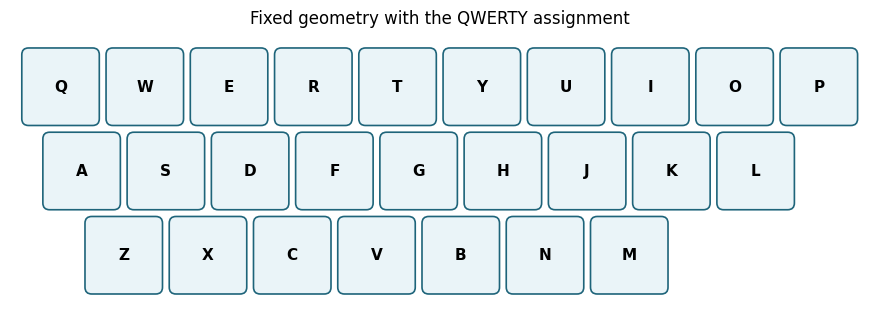

In [5]:
def draw_keyboard(layout, title, ax):
    coordinates = keyboard_coordinates()
    for position, (x_coordinate, y_coordinate) in enumerate(coordinates):
        key = FancyBboxPatch(
            (x_coordinate - 0.43, y_coordinate - 0.43),
            0.86,
            0.86,
            boxstyle="round,pad=0.03,rounding_size=0.08",
            facecolor="#EAF4F8",
            edgecolor="#1E647A",
            linewidth=1.2,
        )
        ax.add_patch(key)
        ax.text(
            x_coordinate,
            y_coordinate,
            layout[position].upper(),
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
        )
    ax.set_xlim(-0.6, 9.6)
    ax.set_ylim(-0.65, 2.65)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)


fig, ax = plt.subplots(figsize=(9, 3.2))
draw_keyboard(QWERTY_LAYOUT, "Fixed geometry with the QWERTY assignment", ax)
fig.tight_layout()
fig.savefig(FIGURE_DIRECTORY / "qwerty_geometry.pdf", bbox_inches="tight")
plt.show()

## 5. Verification before experimentation

The automated tests check preprocessing boundaries, permutation validity,
distance-matrix properties, deterministic costs, crossover and mutation,
exact budgets, fixed-seed reproducibility, adaptive responses, repeated-run
alignment, and statistical summaries. A failed test blocks interpretation of
later results.

In [6]:
test_environment = os.environ.copy()
test_environment["PYTHONPATH"] = str(SOURCE_DIRECTORY) + os.pathsep + test_environment.get(
    "PYTHONPATH", ""
)
test_process = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", str(PROJECT_ROOT / "tests"), "-v"],
    cwd=PROJECT_ROOT,
    env=test_environment,
    text=True,
    capture_output=True,
)
print(test_process.stdout)
print(test_process.stderr)
if test_process.returncode != 0:
    raise RuntimeError("Unit tests failed; do not continue to interpret results.")


test_controller_changes_mutation_rate (test_adaptive_ga.AdaptiveGeneticAlgorithmTests.test_controller_changes_mutation_rate) ... ok
test_exact_budget_valid_layout_and_monotone_history (test_adaptive_ga.AdaptiveGeneticAlgorithmTests.test_exact_budget_valid_layout_and_monotone_history) ... ok
test_fixed_seed_is_reproducible (test_adaptive_ga.AdaptiveGeneticAlgorithmTests.test_fixed_seed_is_reproducible) ... ok
test_positional_diversity_has_expected_bounds (test_adaptive_ga.AdaptiveGeneticAlgorithmTests.test_positional_diversity_has_expected_bounds) ... ok
test_cliffs_delta_direction_for_minimization (test_analysis.AnalysisTests.test_cliffs_delta_direction_for_minimization) ... ok
test_paired_comparison_matches_by_seed (test_analysis.AnalysisTests.test_paired_comparison_matches_by_seed) ... ok
test_summary_has_one_row_per_algorithm (test_analysis.AnalysisTests.test_summary_has_one_row_per_algorithm) ... ok
test_small_suite_has_matched_runs_and_exact_histories (test_experiments.Experiment

## 6. Standard and feedback-adaptive methods

All stochastic methods receive the same number of objective evaluations.
Convergence is therefore compared against evaluations—not generations versus
iterations.

**Adaptive GA.** Population diversity $H_g$ is the mean normalized positional
entropy. Mutation $m_g$ responds to observed search behavior:

$$
m_{g+1}=\begin{cases}
\min(m_{\max},\alpha m_g), & H_g<H_{\min}\;\text{or stagnation}\ge L,\\
\max(m_{\min},\beta m_g), & \text{otherwise}.
\end{cases}
$$

**Adaptive SA.** After geometric cooling, the recent acceptance ratio $r_w$
is measured over a fixed window. Low acceptance triggers reheating; high
acceptance triggers accelerated cooling. This is feedback adaptation, not a
preset schedule.

In [7]:
print("Starting matched-seed benchmark...")
benchmark_start = time.perf_counter()
suite = run_benchmark_suite(
    training_objective,
    testing_objective,
    config=experiment_config,
    progress=print,
)
benchmark_runtime = time.perf_counter() - benchmark_start
print(f"Completed {RUNS} matched runs in {benchmark_runtime:.2f} seconds.")

budget_check = suite.runs.groupby("algorithm", observed=True)["evaluations"].unique()
display(budget_check.to_frame(name="observed evaluation counts"))
assert suite.runs["evaluations"].eq(EVALUATION_BUDGET).all()

Starting matched-seed benchmark...
Run 1/30, seed 100
Run 2/30, seed 101
Run 3/30, seed 102
Run 4/30, seed 103
Run 5/30, seed 104
Run 6/30, seed 105
Run 7/30, seed 106
Run 8/30, seed 107
Run 9/30, seed 108
Run 10/30, seed 109
Run 11/30, seed 110
Run 12/30, seed 111
Run 13/30, seed 112
Run 14/30, seed 113
Run 15/30, seed 114
Run 16/30, seed 115
Run 17/30, seed 116
Run 18/30, seed 117
Run 19/30, seed 118
Run 20/30, seed 119
Run 21/30, seed 120
Run 22/30, seed 121
Run 23/30, seed 122
Run 24/30, seed 123
Run 25/30, seed 124
Run 26/30, seed 125
Run 27/30, seed 126
Run 28/30, seed 127
Run 29/30, seed 128
Run 30/30, seed 129
Completed 30 matched runs in 80.21 seconds.


,observed evaluation counts
algorithm,
Random Search,[10000]
Standard GA,[10000]
Adaptive GA,[10000]
Standard SA,[10000]
Adaptive SA,[10000]


## 7. Quantitative results

The table reports the full distribution across independent runs rather than a
single favorable result. The primary generalization metric is held-out test
cost. Confidence intervals describe uncertainty in each algorithm's mean.

In [8]:
test_summary = summarize_results(suite.runs, metric="test_cost")
improvement_summary = summarize_results(
    suite.runs, metric="test_improvement_over_qwerty_pct"
)
runtime_summary = summarize_results(suite.runs, metric="runtime_seconds")

print("Held-out cost summary — lower is better")
display(test_summary.round(6))
print("Held-out improvement over QWERTY (%) — higher is better")
display(improvement_summary.round(4))
print("Runtime summary (seconds)")
display(runtime_summary.round(6))

Held-out cost summary — lower is better


,algorithm,n,mean,std,median,q1,q3,minimum,maximum,ci95_low,ci95_high
0,Random Search,30,2.403007,0.039313,2.411349,2.367011,2.429810,2.326391,2.480880,2.388328,2.417687
1,Standard GA,30,1.983623,0.021726,1.984379,1.971008,1.993982,1.926126,2.046171,1.975511,1.991736
2,Adaptive GA,30,1.983985,0.013958,1.983398,1.975685,1.989840,1.962035,2.022607,1.978772,1.989197
3,Standard SA,30,1.943039,0.015767,1.943807,1.934365,1.954334,1.904974,1.967661,1.937151,1.948926
4,Adaptive SA,30,1.935234,0.016299,1.937856,1.926688,1.944012,1.896079,1.969344,1.929148,1.941320


Held-out improvement over QWERTY (%) — higher is better


,algorithm,n,mean,std,median,q1,q3,minimum,maximum,ci95_low,ci95_high
0,Random Search,30,26.0932,1.2091,25.8366,25.2688,27.2003,23.6981,28.4496,25.6417,26.5447
1,Standard GA,30,38.9917,0.6682,38.9685,38.6731,39.3797,37.0680,40.7601,38.7422,39.2412
2,Adaptive GA,30,38.9806,0.4293,38.9987,38.8005,39.2359,37.7928,39.6557,38.8203,39.1409
3,Standard SA,30,40.2400,0.4849,40.2163,39.8926,40.5067,39.4827,41.4107,40.0589,40.4210
4,Adaptive SA,30,40.4800,0.5013,40.3994,40.2100,40.7428,39.4309,41.6842,40.2928,40.6672


Runtime summary (seconds)


,algorithm,n,mean,std,median,q1,q3,minimum,maximum,ci95_low,ci95_high
0,Random Search,30,0.421282,0.101106,0.383170,0.370034,0.395322,0.356854,0.676794,0.383528,0.459036
1,Standard GA,30,0.656339,0.281698,0.555681,0.542771,0.590408,0.534042,1.990701,0.551152,0.761527
2,Adaptive GA,30,0.747223,0.185734,0.660190,0.638856,0.676943,0.608205,1.110517,0.677869,0.816577
3,Standard SA,30,0.431000,0.102256,0.384657,0.370071,0.413867,0.355311,0.648448,0.392817,0.469183
4,Adaptive SA,30,0.413808,0.089808,0.383232,0.362380,0.407256,0.346048,0.679178,0.380273,0.447343


### Paired tests and effect sizes

Standard and adaptive variants use matched seeds and the same budgets. The
two-sided Wilcoxon signed-rank test evaluates paired differences. Cliff's delta
adds effect direction and magnitude: for this minimization metric, a negative
delta favors the first-listed adaptive method. Statistical significance is not
treated as practical significance by itself.

In [9]:
comparisons = pd.DataFrame(
    [
        paired_method_comparison(
            suite.runs,
            first_method="Adaptive GA",
            second_method="Standard GA",
            metric="test_cost",
        ),
        paired_method_comparison(
            suite.runs,
            first_method="Adaptive SA",
            second_method="Standard SA",
            metric="test_cost",
        ),
    ]
)
display(comparisons.round(6))

,first_method,second_method,metric,matched_runs,median_paired_difference_first_minus_second,wilcoxon_statistic,p_value,cliffs_delta,effect_magnitude
0,Adaptive GA,Standard GA,test_cost,30,0.000130,231.0,0.983834,-0.008889,negligible
1,Adaptive SA,Standard SA,test_cost,30,-0.002398,159.0,0.134735,-0.281111,small


## 8. Convergence with uncertainty

Solid lines show the mean best-so-far training cost. Shaded bands show the 95%
confidence interval across runs. These curves reveal both convergence speed
and run-to-run variability under the common budget.

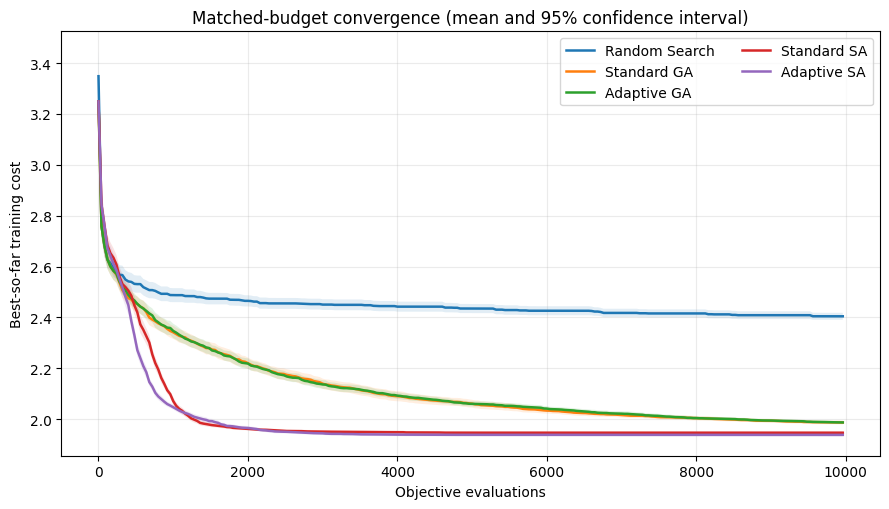

In [10]:
fig, ax = plt.subplots(figsize=(9, 5.2))
sampling_step = max(1, EVALUATION_BUDGET // 250)
evaluation_axis = np.arange(1, EVALUATION_BUDGET + 1)[::sampling_step]

for algorithm in ALGORITHM_ORDER:
    history = suite.histories[algorithm][:, ::sampling_step]
    mean_history = history.mean(axis=0)
    if history.shape[0] > 1:
        margin = 1.96 * history.std(axis=0, ddof=1) / np.sqrt(history.shape[0])
    else:
        margin = np.zeros_like(mean_history)
    ax.plot(evaluation_axis, mean_history, label=algorithm, linewidth=1.8)
    ax.fill_between(
        evaluation_axis,
        mean_history - margin,
        mean_history + margin,
        alpha=0.13,
    )

ax.set_xlabel("Objective evaluations")
ax.set_ylabel("Best-so-far training cost")
ax.set_title("Matched-budget convergence (mean and 95% confidence interval)")
ax.grid(alpha=0.25)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIRECTORY / "convergence_comparison.pdf", bbox_inches="tight")
plt.show()

## 9. Evidence that adaptation occurred

The first matched run is shown diagnostically. Adaptive GA must change mutation
in response to diversity or stagnation. Adaptive SA must change temperature in
response to its measured acceptance ratio. These plots distinguish a genuine
feedback controller from a fixed schedule.

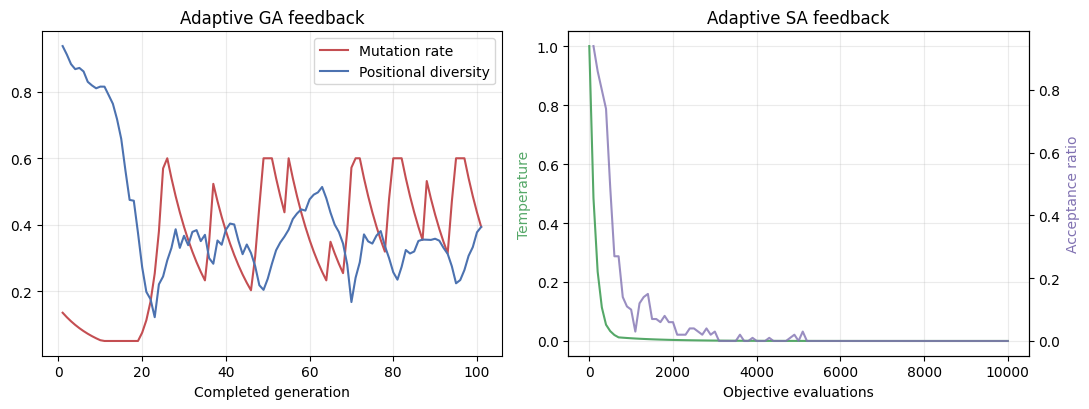

In [11]:
ga_diagnostic = suite.adaptive_ga_diagnostics[0]
sa_diagnostic = suite.adaptive_sa_diagnostics[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

generations = np.arange(1, len(ga_diagnostic["mutation_rate_history"]) + 1)
axes[0].plot(
    generations,
    ga_diagnostic["mutation_rate_history"],
    color="#C44E52",
    label="Mutation rate",
)
axes[0].plot(
    generations,
    ga_diagnostic["diversity_history"],
    color="#4C72B0",
    label="Positional diversity",
)
axes[0].set_xlabel("Completed generation")
axes[0].set_title("Adaptive GA feedback")
axes[0].grid(alpha=0.25)
axes[0].legend()

temperature_points = np.asarray(sa_diagnostic["temperature_history"], dtype=float)
acceptance_points = np.asarray(
    sa_diagnostic["acceptance_ratio_history"], dtype=float
)
axes[1].plot(
    temperature_points[:, 0],
    temperature_points[:, 1],
    color="#55A868",
    label="Temperature",
)
acceptance_axis = axes[1].twinx()
acceptance_axis.plot(
    acceptance_points[:, 0],
    acceptance_points[:, 1],
    color="#8172B2",
    alpha=0.8,
    label="Acceptance ratio",
)
axes[1].set_xlabel("Objective evaluations")
axes[1].set_ylabel("Temperature", color="#55A868")
acceptance_axis.set_ylabel("Acceptance ratio", color="#8172B2")
axes[1].set_title("Adaptive SA feedback")
axes[1].grid(alpha=0.25)

fig.tight_layout()
fig.savefig(FIGURE_DIRECTORY / "adaptation_diagnostics.pdf", bbox_inches="tight")
plt.show()

## 10. Best training-selected layout and qualitative bigram analysis

The displayed optimized layout is selected by training cost only; test cost is
not used for selection. Frequent training bigrams are then inspected to explain
which modeled transitions became shorter or longer relative to QWERTY.

,Field,Value
0,Algorithm,Adaptive SA
1,Seed,103
2,Layout,zgdnalmyxjkwieropbqvchtsuf
3,Training cost,1.899209
4,Testing cost,1.896079
5,Testing improvement over QWERTY (%),41.684246


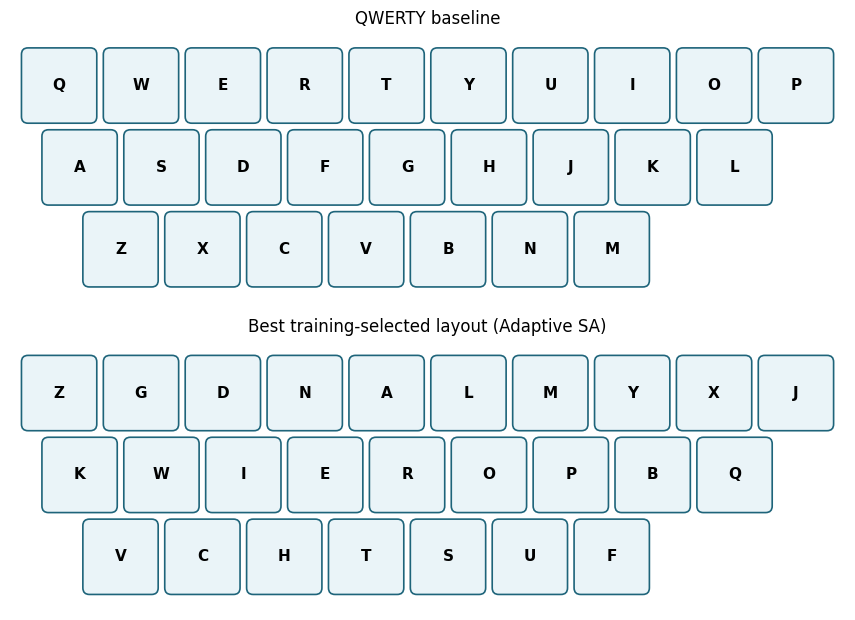

In [12]:
best_training_index = suite.runs["train_cost"].astype(float).idxmin()
best_run = suite.runs.loc[best_training_index]
best_layout = str(best_run["best_layout"])

best_run_table = pd.DataFrame(
    {
        "Field": [
            "Algorithm",
            "Seed",
            "Layout",
            "Training cost",
            "Testing cost",
            "Testing improvement over QWERTY (%)",
        ],
        "Value": [
            best_run["algorithm"],
            int(best_run["seed"]),
            best_layout,
            float(best_run["train_cost"]),
            float(best_run["test_cost"]),
            float(best_run["test_improvement_over_qwerty_pct"]),
        ],
    }
)
display(best_run_table)

fig, axes = plt.subplots(2, 1, figsize=(9, 6.3))
draw_keyboard(QWERTY_LAYOUT, "QWERTY baseline", axes[0])
draw_keyboard(best_layout, f"Best training-selected layout ({best_run['algorithm']})", axes[1])
fig.tight_layout()
fig.savefig(FIGURE_DIRECTORY / "best_layout_comparison.pdf", bbox_inches="tight")
plt.show()

In [13]:
alphabet = "abcdefghijklmnopqrstuvwxyz"
distance_matrix = build_distance_matrix()
qwerty_positions = layout_positions(QWERTY_LAYOUT)
best_positions = layout_positions(best_layout)

top_flat_indices = np.argsort(training_matrix.ravel())[::-1][:12]
bigram_records = []
for flat_index in top_flat_indices:
    first_index, second_index = np.unravel_index(flat_index, training_matrix.shape)
    qwerty_distance = distance_matrix[
        qwerty_positions[first_index], qwerty_positions[second_index]
    ]
    optimized_distance = distance_matrix[
        best_positions[first_index], best_positions[second_index]
    ]
    bigram_records.append(
        {
            "bigram": alphabet[first_index] + alphabet[second_index],
            "normalized_frequency": training_matrix[first_index, second_index],
            "qwerty_distance": qwerty_distance,
            "optimized_distance": optimized_distance,
            "distance_change": optimized_distance - qwerty_distance,
        }
    )

bigram_analysis = pd.DataFrame(bigram_records)
display(bigram_analysis.round(5))

,bigram,normalized_frequency,qwerty_distance,optimized_distance,distance_change
0,th,0.03580,1.60078,1.00000,-0.60078
1,he,0.03310,3.40037,1.11803,-2.28233
2,in,0.02395,2.35850,1.25000,-1.10850
3,er,0.02063,1.00000,1.00000,0.00000
4,an,0.01974,5.59017,1.00000,-4.59017
5,re,0.01805,1.00000,1.00000,0.00000
6,on,0.01654,3.01040,2.46221,-0.54818
7,at,0.01439,3.88104,2.01556,-1.86548
8,en,0.01399,4.25000,1.03078,-3.21922
9,nd,0.01323,3.64005,1.00000,-2.64005


## 11. Runtime and generalization analysis

Runtime is measured in the same notebook session and hardware environment.
The generalization gap is testing cost minus training cost. A method that
optimizes training aggressively but degrades on held-out text may be
over-specializing to the training corpus.

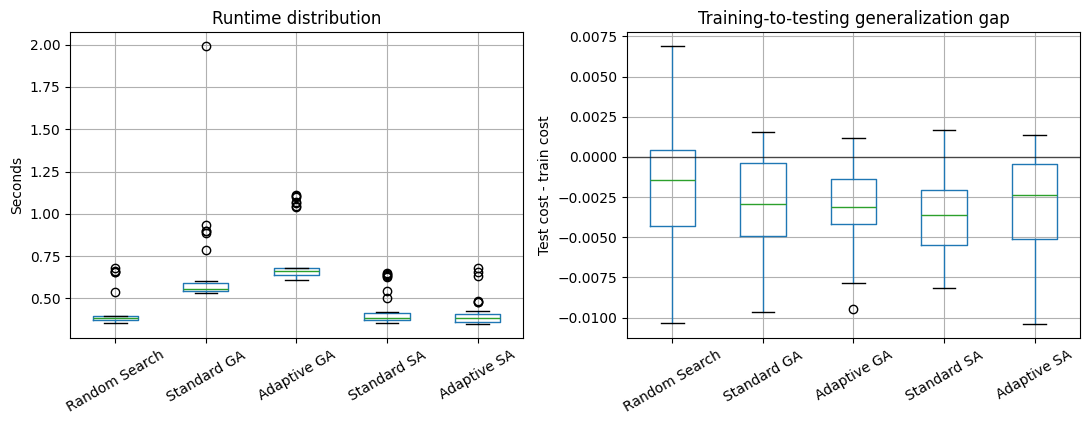

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
suite.runs.boxplot(column="runtime_seconds", by="algorithm", ax=axes[0], rot=30)
axes[0].set_title("Runtime distribution")
axes[0].set_xlabel("")
axes[0].set_ylabel("Seconds")

suite.runs.boxplot(column="generalization_gap", by="algorithm", ax=axes[1], rot=30)
axes[1].axhline(0.0, color="black", linewidth=1, alpha=0.6)
axes[1].set_title("Training-to-testing generalization gap")
axes[1].set_xlabel("")
axes[1].set_ylabel("Test cost - train cost")

fig.suptitle("")
fig.tight_layout()
fig.savefig(FIGURE_DIRECTORY / "runtime_generalization.pdf", bbox_inches="tight")
plt.show()

## 12. Limitations and defensible interpretation

- The Brown Corpus is reproducible but old and may not represent modern chat,
  programming, multilingual, or domain-specific typing.
- The objective ignores punctuation, spaces, key size, finger assignment,
  hand alternation, learning cost, and user-specific motor ability.
- Euclidean center-to-center movement is a model, not a direct measurement of
  speed, fatigue, injury risk, or comfort.
- No human participants or longitudinal adaptation study are included.
- Algorithm parameters should be tuned only with training-only pilots or a
  separate validation set, never using held-out test outcomes.

Accordingly, conclusions must be phrased as reductions in modeled movement
cost under this corpus, geometry, and budget—not as proven ergonomic benefits.

## 13. Export reproducibility artifacts

The final run exports per-run results, compressed convergence histories, exact
algorithm configurations, corpus document identifiers, adaptive diagnostics,
summary tables, statistical comparisons, and publication-ready PDF figures.
These files should be committed to the final GitHub release together with the
executed notebook and source code.

In [15]:
output_directory = RESULTS_DIRECTORY / ("smoke_notebook" if FAST_MODE else "final")
saved_paths = save_benchmark_suite(
    suite,
    output_directory,
    corpus_metadata=corpus_metadata,
)
test_summary.to_csv(output_directory / "test_cost_summary.csv", index=False)
improvement_summary.to_csv(
    output_directory / "test_improvement_summary.csv", index=False
)
runtime_summary.to_csv(output_directory / "runtime_summary.csv", index=False)
comparisons.to_csv(output_directory / "paired_statistical_tests.csv", index=False)
bigram_analysis.to_csv(output_directory / "top_bigram_analysis.csv", index=False)

bundle_stem = "smoke_results_bundle" if FAST_MODE else "final_results_bundle"
bundle_path = Path(
    shutil.make_archive(
        str(PROJECT_ROOT / bundle_stem),
        "zip",
        root_dir=RESULTS_DIRECTORY,
    )
)

print("Saved reproducibility artifacts:")
for name, path in saved_paths.items():
    print(f"- {name}: {path}")
print(f"- tables: {output_directory}")
print(f"- figures: {FIGURE_DIRECTORY}")
print(f"- downloadable result bundle: {bundle_path}")

Saved reproducibility artifacts:
- runs: /content/keyboard-layout-optimization/results/final/run_results.csv
- histories: /content/keyboard-layout-optimization/results/final/convergence_histories.npz
- metadata: /content/keyboard-layout-optimization/results/final/experiment_metadata.json
- diagnostics: /content/keyboard-layout-optimization/results/final/adaptation_diagnostics.json
- tables: /content/keyboard-layout-optimization/results/final
- figures: /content/keyboard-layout-optimization/results/figures
- downloadable result bundle: /content/keyboard-layout-optimization/final_results_bundle.zip


## 14. IEEE-paper mapping and final checklist

- **Introduction:** motivation, scope, contribution, and four research questions.
- **Related Work:** corrected Assignment 3 synthesis; do not copy unsupported
  cross-paper percentages as directly comparable results.
- **Problem Formulation:** permutation, geometry, bigram matrix, objective, and
  assumptions.
- **Proposed Solution:** standard GA/SA plus feedback equations for adaptive
  mutation and acceptance-ratio temperature control.
- **Performance Evaluation:** Brown split, budgets, 30 seeds, distributional
  statistics, paired tests, effect sizes, convergence, runtime, and held-out
  results.
- **Conclusions:** evidence-based findings, limitations, and specific future work.

Before submission: run **Restart and Run All** in final mode, confirm every cell
finishes, save the outputs, replace the author placeholders, create a GitHub
release or commit permalink, and insert that permanent URL in the IEEE paper.